# Phase 1 - Data Ingestion & Validation

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis
**Client case:** Atlantic Recording Corporation
**Notebook:** `notebooks/01_data_ingestion_and_validation.ipynb`

---

## What this notebook does (in plain English)

Think of this notebook as the **security check at an airport, but for data**. Before we analyze anything we must be sure the data is real, complete, correctly typed and not double-counted. If we skip this, every chart, KPI, statistical test and model that comes later can be quietly wrong.

| Section | The question we answer |
|---|---|
| 1. Setup | Where are my files, and what rules should the data follow? |
| 2. Ingestion | Does the file load, and does it look like what the brief promised? |
| 3. Types, missing values, dates | Are dates real dates? Is anything missing? Are there missing days? |
| 4. Rank check | Is every position between 1 and 50, and is every day complete? |
| 5. Duplicates | Is any song counted twice for the same day? |
| 6. Text standardization | Are artist and song names written consistently? What identifies a *song*? |
| 7. Value checks | Are popularity, duration, album type, track count and the explicit flag sensible? |
| 8. Scorecard | One table that summarizes every check (PASS / WARN / FAIL / INFO) |
| 9. Save | Write the validated data and the quality report to disk |

### How every cell is explained
Above each code cell you will find five short lines:

- **What this code is** - the plain-English description
- **Why we need it** - the reason this step exists
- **What will happen** - what Python does when you press Run
- **Expected outcome** - what you should see (real numbers are given, so you can confirm your result matches)
- **Motive** - the bigger goal this step serves

> **Golden rule of this phase:** *find and flag problems; do not silently fix them.* Every fix is a decision. Decisions are written in the **Decision log** (Step 8.3) so they can be defended in the research paper.

> **Tip:** run the cells from top to bottom. If anything looks odd after re-running individual cells, restart the kernel and use **Run All**.

## Section 1 - Setup

### Step 1.1 - Import the libraries

**What this code is:** A list of tools (libraries) we borrow so we do not have to write everything from scratch.

**Why we need it:** Python only knows its basic commands. `pandas` handles tables, `numpy` handles numbers, `matplotlib` and `seaborn` draw charts, `pathlib` handles file locations, `re` finds patterns in text and `unicodedata` cleans special characters (accents, curly quotes).

**What will happen:** Python loads each library into memory. Nothing is calculated yet.

**Expected outcome:** Two lines showing your pandas and numpy versions. No errors.

**Motive:** Every later step depends on these tools, so we load them once, at the very top.

In [1]:
from pathlib import Path          # builds file paths that work on Windows, macOS and Linux
import re                         # regular expressions = pattern matching inside text
import unicodedata                # standard way to clean special characters in text
import warnings                   # lets us silence harmless warnings on purpose

import numpy as np                # fast maths on arrays of numbers
import pandas as pd               # the main tool for working with tables (DataFrames)

import matplotlib.pyplot as plt   # basic charting library
import seaborn as sns             # prettier statistical charts built on top of matplotlib

print("pandas version:", pd.__version__)
print("numpy  version:", np.__version__)

pandas version: 2.3.2
numpy  version: 2.3.3


### Step 1.2 - Display and chart settings

**What this code is:** A few one-time settings that control how tables and charts look.

**Why we need it:** By default pandas hides columns and cuts long text, which makes inspection hard. A consistent chart style also makes the final report look professional.

**What will happen:** We change pandas display options, choose a chart theme and define one small colour palette for the whole project.

**Expected outcome:** No visible output. Every later table and chart follows these settings.

**Motive:** Good inspection needs full visibility, and consistent visuals build trust in the final deliverables.

In [2]:
pd.set_option("display.max_columns", 50)       # show up to 50 columns instead of hiding some
pd.set_option("display.width", 200)            # use a wider print area so tables do not wrap
pd.set_option("display.max_colwidth", 70)      # show up to 70 characters of long text cells
pd.set_option("display.float_format", "{:,.2f}".format)   # numbers appear as 12,345.68

sns.set_theme(style="whitegrid", context="notebook")      # clean white background with a light grid
plt.rcParams["figure.figsize"] = (11, 4.5)                # default chart size (width, height in inches)
plt.rcParams["axes.titleweight"] = "bold"                 # make chart titles bold

# One small colour palette used across the whole project, so every chart looks like it belongs together
COLORS = {
    "primary": "#1F4E79",   # deep blue -> normal / main series
    "accent":  "#E07A1F",   # orange    -> highlights and warnings
    "good":    "#2E8B57",   # green     -> passed / healthy
    "bad":     "#C0392B",   # red       -> problems
    "grey":    "#7F8C8D",   # grey      -> neutral / background items
}

### Step 1.3 - Define project folders and file paths

**What this code is:** Variables that store *where* things live: the raw data, the folder for validated data and the folder for reports.

**Why we need it:** Hard-coding something like `C:\Users\YourName\Desktop\data.csv` breaks the moment the project moves to another computer. Paths built from the project root work everywhere.

**What will happen:** Python works out the project root (one level above the `notebooks` folder), builds each path, creates any folder that is missing and checks that the raw CSV exists.

**Expected outcome:** A line saying the raw file was **FOUND**. If it says NOT FOUND, copy `Atlantic_United_States.csv` into `data/raw/` and run the cell again.

**Motive:** Reproducibility. Anyone who downloads the project can run it without editing a single path.

In [3]:
# If this notebook is opened from the 'notebooks' folder, the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_FILE    = PROJECT_ROOT / "data" / "raw" / "Atlantic_United_States.csv"   # the original file (never edited)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"                              # validated, not yet analysis-ready
REPORTS_DIR = PROJECT_ROOT / "reports"                                       # tables and documents for the paper
FIGURES_DIR = REPORTS_DIR / "figures"                                        # saved charts

for folder in (INTERIM_DIR, REPORTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)     # create the folder if it does not exist yet

print("Project root:", PROJECT_ROOT)
print("Raw file    :", RAW_FILE.name, "->", "FOUND" if RAW_FILE.exists() else "NOT FOUND")
assert RAW_FILE.exists(), "Copy Atlantic_United_States.csv into data/raw/ and run this cell again."

Project root: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics
Raw file    : Atlantic_United_States.csv -> FOUND


### Step 1.4 - Write down the "data contract" (what the data *should* look like)

**What this code is:** A dictionary of expectations: which columns must exist, and which business rules every row must obey (rank 1-50, popularity 0-100, and so on). They come straight from the project brief.

**Why we need it:** You cannot validate data without a definition of "valid". Writing the rules once, in one place, means every check below uses the same numbers, and the rules can be reviewed or changed easily.

**What will happen:** Python stores the expected columns and the rule values in variables, then prints the column list. Nothing is checked yet.

**Expected outcome:** A printout of the 10 expected columns with their meaning.

**Motive:** Professional teams call this a *data contract*. It turns a vague feeling ("the data looks fine") into testable statements ("rank must be between 1 and 50").

In [4]:
# Columns promised by the project brief (name -> meaning)
EXPECTED_COLUMNS = {
    "date":            "Date of the playlist snapshot",
    "position":        "Playlist rank (1-50)",
    "song":            "Song title",
    "artist":          "Artist(s)",
    "popularity":      "Popularity score from the Atlantic API",
    "duration_ms":     "Song duration in milliseconds",
    "album_type":      "Single / Album",
    "total_tracks":    "Number of tracks in the album",
    "is_explicit":     "Explicit content flag",
    "album_cover_url": "Album artwork URL",
}

# Business rules every row must obey
RULES = {
    "date_format":         "%d-%m-%Y",       # the CSV writes dates like 18-05-2024 (day-month-year)
    "rank_min":            1,
    "rank_max":            50,
    "rows_per_snapshot":   50,               # a Top 50 playlist has exactly 50 rows per day
    "popularity_min":      0,
    "popularity_max":      100,
    "duration_min_ms":     30_000,           # 30 seconds - anything shorter would be suspicious
    "duration_max_ms":     20 * 60_000,      # 20 minutes - anything longer is not a normal song
    "allowed_album_types": {"single", "album"},   # exactly what the brief lists
}

print("Expected columns:")
for name, meaning in EXPECTED_COLUMNS.items():
    print(f"  {name:<16} {meaning}")

Expected columns:
  date             Date of the playlist snapshot
  position         Playlist rank (1-50)
  song             Song title
  artist           Artist(s)
  popularity       Popularity score from the Atlantic API
  duration_ms      Song duration in milliseconds
  album_type       Single / Album
  total_tracks     Number of tracks in the album
  is_explicit      Explicit content flag
  album_cover_url  Album artwork URL


### Step 1.5 - Build a small "quality logger"

**What this code is:** A reusable function, `log_check(...)`, that records the result of every validation check into one list called `dq_log`.

**Why we need it:** We are going to run about 30 checks. If each one only prints a message, we lose track of them. By logging each result in a structured way, we can build one *Data Quality Scorecard* table at the end.

**What will happen:** Python defines the function and an empty list. No check runs yet.

**Expected outcome:** No output. From now on every check prints one line such as `[PASS] ...` or `[WARN] ...` and also stores the result.

**Motive:** Consistent, auditable validation: every check has a name, a rule, a count of affected items and a status. Re-running a cell replaces its old result, so the scorecard never shows duplicates.

In [5]:
dq_log = []   # every check adds one dictionary (one row of the final scorecard) to this list


def log_check(dimension, check, rule, affected, total, unit="rows", severity="WARN", action=""):
    """
    Record one data-quality check.

    dimension : quality dimension - Structure, Completeness, Validity, Uniqueness, Consistency or Coverage
    check     : short, unique name of the check
    rule      : the rule written in plain words
    affected  : how many items broke the rule (0 means the check passed)
    total     : how many items were examined
    unit      : what 'affected' counts - rows, days, tracks, columns ...
    severity  : status to use when the rule is broken - FAIL (must fix), WARN (handle later) or INFO (just note it)
    action    : what we plan to do about it (shown in the final scorecard)
    """
    status = "PASS" if affected == 0 else severity
    pct = (affected / total * 100) if total else 0.0
    dq_log[:] = [row for row in dq_log if row["check"] != check]     # re-running a cell replaces its old result
    dq_log.append({
        "dimension": dimension, "check": check, "rule": rule,
        "affected": int(affected), "total": int(total), "unit": unit,
        "pct_affected": round(pct, 2), "status": status, "action": action,
    })
    print(f"[{status:<4}] {check}: {int(affected):,} of {int(total):,} {unit} ({pct:.2f}%)")

## Section 2 - Ingestion (loading the raw data)

### Step 2.1 - Load the raw CSV and keep an untouched copy

**What this code is:** One command (`pd.read_csv`) that reads the CSV file into a pandas table (a *DataFrame*), followed by a safety copy.

**Why we need it:** All analysis starts by getting data into memory. We keep `df_raw` exactly as it came from the file and do all our work on a copy called `df`. If we ever make a mistake we can compare against `df_raw`, or simply start again from it.

**What will happen:** Python reads about 3.6 MB of text, turns it into a table and reports its size on disk and in memory.

**Expected outcome:** `Loaded 27,800 rows x 10 columns`.

**Motive:** The raw layer is sacred. Professional pipelines never edit the original file; they always work on copies (this is the "bronze layer" idea in data engineering).

In [6]:
df_raw = pd.read_csv(RAW_FILE)     # read the CSV into a DataFrame
df = df_raw.copy()                 # we work on this copy; df_raw stays untouched

size_disk_mb = RAW_FILE.stat().st_size / 1_048_576
size_ram_mb  = df_raw.memory_usage(deep=True).sum() / 1_048_576

print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Size on disk: {size_disk_mb:.2f} MB | Size in memory: {size_ram_mb:.2f} MB")

Loaded 27,800 rows x 10 columns
Size on disk: 3.63 MB | Size in memory: 10.31 MB


### Step 2.2 - Take a first look (head, tail and a random sample)

**What this code is:** Three quick previews: the first 5 rows, the last 5 rows and 5 random rows.

**Why we need it:** A number like "27,800 rows" tells you nothing about what a row *looks like*. Looking at the top, the bottom and a random sample catches obvious surprises: odd formats, strange text, a file that is cut off at the end.

**What will happen:** Pandas prints three small tables.

**Expected outcome:** The first row is *Ella Baila Sola* by *Eslabon Armado* at position 1 on `18-05-2024`. Notice that the date is written **day-month-year**, and that collaborating artists are joined with `&` (for example `Lil Durk & J. Cole`).

**Motive:** Build a mental picture of the data before testing it. Many data problems are visible to the human eye in the first 30 seconds.

In [7]:
print("FIRST 5 ROWS")
display(df.head())

print("LAST 5 ROWS")
display(df.tail())

print("5 RANDOM ROWS (random_state is fixed, so you see the same rows every time)")
display(df.sample(5, random_state=42))

FIRST 5 ROWS


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,Ella Baila Sola,Eslabon Armado,89,165671,album,16,False,https://i.scdn.co/image/ab67616d0000b273dfddf1cb31b85a6d28b7d91f
1,18-05-2024,2,Last Night,Morgan Wallen,89,163854,album,36,True,https://i.scdn.co/image/ab67616d0000b273705079df9a25a28b452c1fc9
2,18-05-2024,3,All My Life (feat. J. Cole),Lil Durk & J. Cole,84,223878,single,1,True,https://i.scdn.co/image/ab67616d0000b2737c173b0dc64913d4635e3594
3,18-05-2024,4,un x100to,Grupo Frontera & Bad Bunny,99,194563,single,1,False,https://i.scdn.co/image/ab67616d0000b273716c0b0ad51594ff788b5f06
4,18-05-2024,5,Kill Bill,SZA,94,153946,album,23,False,https://i.scdn.co/image/ab67616d0000b2730c471c36970b9406233842a5


LAST 5 ROWS


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
27795,27-11-2025,46,Love Somebody,Morgan Wallen,86,204828,single,1,False,https://i.scdn.co/image/ab67616d0000b2734b86223903ecefaa8df576a4
27796,27-11-2025,47,HOT TO GO!,Chappell Roan,88,184841,album,14,False,https://i.scdn.co/image/ab67616d0000b27396fa88fb1789be437d5cb4b6
27797,27-11-2025,48,Sweater Weather,The Neighbourhood,90,240400,album,11,False,https://i.scdn.co/image/ab67616d0000b2738265a736a1eb838ad5a0b921
27798,27-11-2025,49,Stick Season,Noah Kahan,87,182346,album,14,False,https://i.scdn.co/image/ab67616d0000b2736ee35072df1af802cca09918
27799,27-11-2025,50,Bed Chem,Sabrina Carpenter,90,171869,album,12,False,https://i.scdn.co/image/ab67616d0000b273fd8d7a8d96871e791cb1f626


5 RANDOM ROWS (random_state is fixed, so you see the same rows every time)


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
22811,20-08-2025,12,Pink Pony Club,Chappell Roan,88,258034,album,14,False,https://i.scdn.co/image/ab67616d0000b27396fa88fb1789be437d5cb4b6
6032,15-09-2024,33,Tourniquet,Zach Bryan,85,189053,album,16,True,https://i.scdn.co/image/ab67616d0000b273e5a25ed08d1e7e0fbb440cef
23468,02-09-2025,19,Beautiful Things,Benson Boone,91,180304,album,15,False,https://i.scdn.co/image/ab67616d0000b273cc04ff3e70e146ba9abacf40
10884,21-12-2024,35,Mistletoe,Justin Bieber,92,182946,album,15,False,https://i.scdn.co/image/ab67616d0000b273af0aff7f601df9ed6d2d531d
3711,31-07-2024,12,TELEKINESIS,Travis Scott,83,353754,album,19,True,https://i.scdn.co/image/ab67616d0000b273881d8d8378cd01099babcd44


### Step 2.3 - Check the structure: columns and data types

**What this code is:** A comparison between the columns we *expected* (the data contract) and the columns we *received*, followed by a table of every column's data type.

**Why we need it:** A renamed, missing or extra column silently breaks every formula that comes later. Data types matter too: a date stored as text cannot be sorted or filtered by time.

**What will happen:** Python compares two lists, logs the result and prints each column's type and number of non-null values (`df.info()`).

**Expected outcome:** `[PASS]` for missing columns and `[PASS]` for extra columns. In the info table `date` is text (`object` or `str`, depending on your pandas version) - we fix that in the next step. `position`, `popularity`, `duration_ms` and `total_tracks` are integers and `is_explicit` is `bool`.

**Motive:** Confirm that the file matches the project brief before investing time in analysis.

In [8]:
expected_cols = list(EXPECTED_COLUMNS)
received_cols = list(df.columns)

missing_cols = [c for c in expected_cols if c not in received_cols]   # promised but not delivered
extra_cols   = [c for c in received_cols if c not in expected_cols]   # delivered but not promised

log_check("Structure", "No expected column is missing", "All 10 columns from the brief exist",
          len(missing_cols), len(expected_cols), unit="columns", severity="FAIL",
          action="Stop and re-export the data")
log_check("Structure", "No unexpected extra column", "Only the 10 columns from the brief exist",
          len(extra_cols), len(received_cols), unit="columns", severity="WARN",
          action="Review the extra columns")

print("\nColumn order matches the brief:", received_cols == expected_cols)
print("\nData types and non-null counts:")
df.info()

[PASS] No expected column is missing: 0 of 10 columns (0.00%)
[PASS] No unexpected extra column: 0 of 10 columns (0.00%)

Column order matches the brief: True

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             27800 non-null  object
 1   position         27800 non-null  int64 
 2   song             27800 non-null  object
 3   artist           27800 non-null  object
 4   popularity       27800 non-null  int64 
 5   duration_ms      27800 non-null  int64 
 6   album_type       27800 non-null  object
 7   total_tracks     27800 non-null  int64 
 8   is_explicit      27800 non-null  bool  
 9   album_cover_url  27800 non-null  object
dtypes: bool(1), int64(4), object(5)
memory usage: 1.9+ MB


## Section 3 - Data types, missing values and date coverage

### Step 3.1 - Convert text to real dates and make sure numbers are numbers

**What this code is:** Three parts. (1) A tiny experiment showing why we never let pandas *guess* a date format. (2) The real conversion of the `date` column into proper datetime values. (3) A safe conversion of the numeric columns.

**Why we need it:** Right now `date` is just text such as `"18-05-2024"`. Text cannot be sorted by time, grouped by month or used to find missing days. The danger: when pandas guesses the format from the *first* row and that row is ambiguous (like `03-04-2025`, which could be 3 April or 4 March), it can read it month-first and then fail on every date such as `18-05-2024`. We remove all doubt by stating the format ourselves: day-month-year.

**What will happen:** The toy example prints how a guess goes wrong. Then every date is converted with `format="%d-%m-%Y"`. A value that cannot be converted becomes `NaT` (the date version of "missing") instead of crashing, and we count them. The numeric columns are converted the same safe way.

**Expected outcome:** In the toy example the second date turns into `NaT`. For the real data you should see **0 unparseable dates** and a range from **2024-05-18** to **2025-11-27**.

**Motive:** Dates are the backbone of a time-series project (rank movement, days on chart, trends). A wrongly read date silently damages everything built on top of it.

In [9]:
# --- Part 1: a tiny experiment - what happens when pandas has to GUESS the format ---
toy = pd.Series(["03-04-2025", "18-05-2024"])      # first value is ambiguous, second is clearly 18 May
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                # hide pandas' own warning so the demo output stays clean
    guessed = pd.to_datetime(toy, errors="coerce")
print(pd.DataFrame({"text": toy, "guessed_by_pandas": guessed}))
print("-> pandas guessed month-first from the first row, so the second date failed (NaT).\n")

# --- Part 2: the real conversion, with the format stated explicitly ---
df["date"] = pd.to_datetime(df["date"], format=RULES["date_format"], errors="coerce")
bad_dates = int(df["date"].isna().sum())
log_check("Validity", "Dates parse with DD-MM-YYYY", "Every date matches the DD-MM-YYYY pattern",
          bad_dates, len(df), severity="FAIL", action="Inspect the raw text of the failing rows")

# --- Part 3: make sure the numeric columns really are numbers ---
numeric_cols = ["position", "popularity", "duration_ms", "total_tracks"]
for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors="coerce")              # text such as "abc" would become NaN
    newly_missing = int(converted.isna().sum() - df[col].isna().sum())
    log_check("Validity", f"{col} is numeric", "Every value can be read as a number",
              newly_missing, len(df), severity="FAIL", action="Inspect the raw text of the failing rows")
    df[col] = converted

print("\nDate range:", df["date"].min().date(), "->", df["date"].max().date())
print("\nColumn types after conversion:")
print(df.dtypes.to_string())

         text guessed_by_pandas
0  03-04-2025        2025-03-04
1  18-05-2024               NaT
-> pandas guessed month-first from the first row, so the second date failed (NaT).

[PASS] Dates parse with DD-MM-YYYY: 0 of 27,800 rows (0.00%)
[PASS] position is numeric: 0 of 27,800 rows (0.00%)
[PASS] popularity is numeric: 0 of 27,800 rows (0.00%)
[PASS] duration_ms is numeric: 0 of 27,800 rows (0.00%)
[PASS] total_tracks is numeric: 0 of 27,800 rows (0.00%)

Date range: 2024-05-18 -> 2025-11-27

Column types after conversion:
date               datetime64[ns]
position                    int64
song                       object
artist                     object
popularity                  int64
duration_ms                 int64
album_type                 object
total_tracks                int64
is_explicit                  bool
album_cover_url            object


### Step 3.2 - Missing-value audit (including *disguised* missing values)

**What this code is:** A table that counts missing values per column, plus a second test that hunts for *disguised* missing values: empty text, text that is only spaces, and placeholders such as "N/A" or "unknown".

**Why we need it:** Real missing values (`NaN`) are easy to find. The dangerous ones are disguised - a blank string, or a `0` that really means "we do not know". Pandas treats them as normal data, so they quietly distort averages and charts.

**What will happen:** Python counts `NaN` per column, then looks inside the text columns for blank or placeholder-looking values.

**Expected outcome:** **0 missing values** in every column and **0 blank/placeholder text values**. (A third kind of disguised missing value - popularity stored as `0` - turns up later, in Step 7.2.)

**Motive:** Completeness is the first quality dimension. We prove it with evidence instead of assuming it.

In [10]:
# 1) Genuine missing values (NaN / NaT)
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing)

log_check("Completeness", "No missing values (NaN) in any column", "Every cell is filled",
          int(df.isna().any(axis=1).sum()), len(df), severity="FAIL",
          action="Decide per column: drop, fill or flag")

# 2) Disguised missing values in text columns: blanks and common placeholders
placeholders = {"", "n/a", "na", "null", "none", "unknown", "nan", "-", "?"}
text_cols = ["song", "artist", "album_type", "album_cover_url"]

disguised_rows = pd.Series(False, index=df.index)
for col in text_cols:
    cleaned = df[col].astype("string").str.strip().str.casefold()    # trim spaces + ignore upper/lower case
    disguised_rows = disguised_rows | cleaned.isin(placeholders).fillna(False).astype(bool)

log_check("Completeness", "No blank or placeholder text", "No empty strings or N/A-style values in text columns",
          int(disguised_rows.sum()), len(df), severity="FAIL", action="Treat as missing")

,missing_count,missing_pct
date,0,0.00
position,0,0.00
song,0,0.00
artist,0,0.00
popularity,0,0.00
duration_ms,0,0.00
album_type,0,0.00
total_tracks,0,0.00
is_explicit,0,0.00
album_cover_url,0,0.00


[PASS] No missing values (NaN) in any column: 0 of 27,800 rows (0.00%)
[PASS] No blank or placeholder text: 0 of 27,800 rows (0.00%)


### Step 3.3 - Date coverage: range, gaps and "rows per day"

**What this code is:** A calendar check. We build the full list of calendar days between the first and last date, compare it with the days that actually appear in the data, and count how many rows each day has.

**Why we need it:** A daily Top 50 should have **exactly 50 rows every day**. A missing day creates a hole in every trend line, and a day with too many rows would double-count songs in "days on chart".

**What will happen:** Python lists the missing days, finds days whose row count is not 50 and draws a timeline: the blue line is the row count, red dots are missing days, the orange dot is a day with extra rows.

**Expected outcome:** 555 dates present in a 559-day window, so **4 missing days** (2025-03-14, 2025-03-25, 2025-07-11, 2025-08-13). One date, **2025-03-01, has 100 rows**. The chart shows one orange dot and four red dots.

**Motive:** Time-based KPIs (days on chart, rank movement, rolling averages) are only correct if the calendar is complete and each day is counted once.

Days in the window      : 559
Days present in the data: 555
Missing days            : 4 -> ['2025-03-14', '2025-03-25', '2025-07-11', '2025-08-13']
Days with != 50 rows    : 1 -> {'2025-03-01': 100}
[WARN] No missing calendar days: 4 of 559 days (0.72%)
[WARN] Exactly 50 rows per date: 1 of 555 days (0.18%)


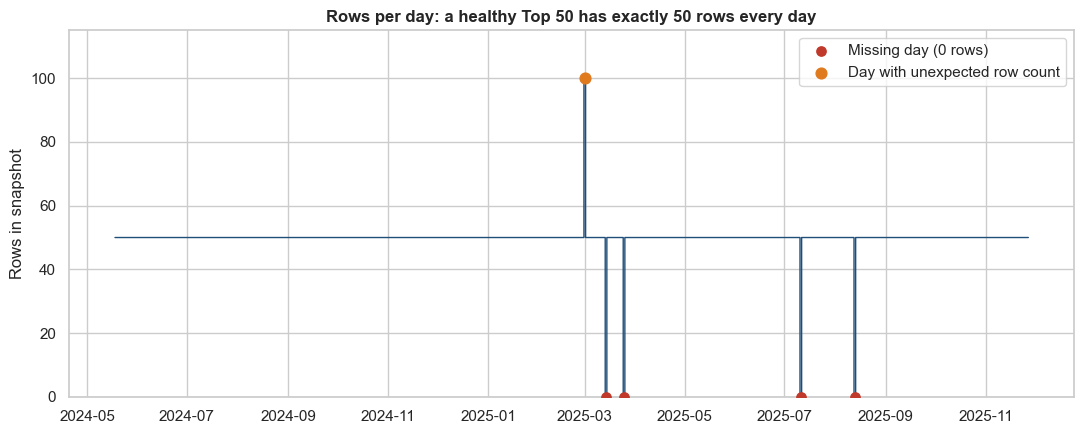

In [11]:
first_day, last_day = df["date"].min(), df["date"].max()
calendar = pd.date_range(first_day, last_day, freq="D")                    # every calendar day in the window

rows_per_day = df.groupby("date").size().reindex(calendar, fill_value=0)   # 0 rows for days with no data
missing_days = rows_per_day[rows_per_day == 0].index
odd_days     = rows_per_day[(rows_per_day != RULES["rows_per_snapshot"]) & (rows_per_day > 0)]

print(f"Days in the window      : {len(calendar)}")
print(f"Days present in the data: {(rows_per_day > 0).sum()}")
print(f"Missing days            : {len(missing_days)} -> {[d.strftime('%Y-%m-%d') for d in missing_days]}")
print(f"Days with != 50 rows    : {len(odd_days)} -> { {d.strftime('%Y-%m-%d'): int(n) for d, n in odd_days.items()} }")

log_check("Coverage", "No missing calendar days", "Every day between first and last date has a snapshot",
          len(missing_days), len(calendar), unit="days", severity="WARN",
          action="Do not invent rows; make time features gap-aware")
log_check("Coverage", "Exactly 50 rows per date", "Each snapshot has 50 rows",
          len(odd_days), int((rows_per_day > 0).sum()), unit="days", severity="WARN",
          action="Investigate (Step 5.2) and keep one snapshot per date")

# Timeline chart
fig, ax = plt.subplots()
ax.plot(rows_per_day.index, rows_per_day.values, color=COLORS["primary"], lw=1, drawstyle="steps-mid")
ax.scatter(missing_days, rows_per_day.loc[missing_days], color=COLORS["bad"], s=45, zorder=3,
           label="Missing day (0 rows)")
ax.scatter(odd_days.index, odd_days.values, color=COLORS["accent"], s=60, zorder=3,
           label="Day with unexpected row count")
ax.set_title("Rows per day: a healthy Top 50 has exactly 50 rows every day")
ax.set_ylabel("Rows in snapshot")
ax.set_ylim(0, 115)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p1_rows_per_day.png", dpi=150)
plt.show()

## Section 4 - Rank (position) validation

### Step 4.1 - Is every rank a whole number between 1 and 50, and is every day complete?

**What this code is:** Four rank tests: (1) values inside 1-50, (2) whole numbers only, (3) every date contains each rank 1-50, (4) no rank appears twice on the same date.

**Why we need it:** The brief explicitly asks us to "validate rank range (1–50)". Rank is the main measure of success in this project; a rank of 0, 51 or 7.5 would be an error. A day with a missing rank, or the same rank twice, breaks rank-movement calculations.

**What will happen:** Python checks the minimum and maximum, tests for decimals, counts how many distinct ranks each date has and counts how many (date, rank) pairs repeat.

**Expected outcome:** `[PASS]` for range, whole numbers and completeness. One `[WARN]`: **50 extra rows** where a (date, rank) pair repeats — all on 2025-03-01 (explained in Step 5.2).

**Motive:** Rank is the base of KPIs such as Average Rank, Best Rank and Rank Volatility. If rank is wrong, every KPI built on it is wrong.

In [12]:
rank = df["position"]
lo, hi = RULES["rank_min"], RULES["rank_max"]

print(f"Smallest rank: {rank.min()} | Largest rank: {rank.max()}")

out_of_range = ~rank.between(lo, hi)            # True where the rank is outside 1..50
not_whole    = (rank % 1 != 0)                  # True where the rank has a decimal part
log_check("Validity", "Rank inside 1-50", f"{lo} <= position <= {hi}",
          int(out_of_range.sum()), len(df), severity="FAIL", action="Drop or correct the rows")
log_check("Validity", "Rank is a whole number", "position has no decimals",
          int(not_whole.sum()), len(df), severity="FAIL", action="Drop or correct the rows")

# Does every date contain all 50 ranks?
per_day = df.groupby("date")["position"].agg(rows="size", distinct_ranks="nunique")
incomplete_days = per_day[per_day["distinct_ranks"] != hi]
log_check("Completeness", "Every date has all ranks 1-50", "Each date contains 50 distinct ranks",
          len(incomplete_days), len(per_day), unit="days", severity="FAIL", action="Investigate the day")

# Does any rank appear twice on the same date?
repeated_rank_rows = int(df.duplicated(["date", "position"]).sum())       # counts the 2nd copy of each pair
log_check("Uniqueness", "No rank repeated within a date", "Each (date, position) pair is unique",
          repeated_rank_rows, len(df), severity="WARN", action="Keep one snapshot per date (Step 5.2)")

counts = rank.value_counts()
if counts.min() == counts.max():
    print(f"\nEvery rank appears exactly {counts.min()} times in the file (555 dates + 1 extra block on 2025-03-01).")
else:
    print(f"\nRanks appear between {counts.min()} and {counts.max()} times in the file - investigate the difference.")

Smallest rank: 1 | Largest rank: 50
[PASS] Rank inside 1-50: 0 of 27,800 rows (0.00%)
[PASS] Rank is a whole number: 0 of 27,800 rows (0.00%)
[PASS] Every date has all ranks 1-50: 0 of 555 days (0.00%)
[WARN] No rank repeated within a date: 50 of 27,800 rows (0.18%)

Every rank appears exactly 556 times in the file (555 dates + 1 extra block on 2025-03-01).


## Section 5 - Duplicate checks

### Step 5.1 - Four kinds of duplicates

**What this code is:** Four different duplicate tests, from strictest to loosest: identical rows; the same (date, position); the same (date, song, artist); and the same (date, song title) only.

**Why we need it:** The brief asks us to check "duplicate song-date entries". But *duplicate* can mean different things. Comparing the third and fourth tests also teaches an important lesson: a song title on its own is **not** a safe identifier, because different artists can release songs with the same title.

**What will happen:** Python counts the extra copies under each rule, lists the dates that contain duplicates and shows the rows where only the *title* repeats.

**Expected outcome:** 10 identical rows; 50 repeated (date, position) pairs; 48 repeated (date, song, artist) combinations; and **50** repeated (date, song title) combinations. All of them sit on **2025-03-01**, except the 2-row gap between 48 and 50: that gap is two *different* songs that share a title on the same day (*Ghostbusters* on 2024-11-01 and *Christmas (Baby Please Come Home)* on 2024-12-25).

**Motive:** Duplicates inflate "Days on Chart" and every count-based KPI. We also settle the right *identity* of a song: **song title + artist**, never the title alone.

In [13]:
n = len(df)
original_cols = list(EXPECTED_COLUMNS)       # compare only the 10 original columns (later helper columns must not interfere)

dup_exact = df.duplicated(subset=original_cols, keep="first")             # whole row identical to an earlier row
dup_pos   = df.duplicated(["date", "position"], keep="first")             # same rank twice on one date
dup_track = df.duplicated(["date", "song", "artist"], keep="first")       # same song + artist twice on one date
dup_title = df.duplicated(["date", "song"], keep="first")                 # same title twice on one date

summary = pd.DataFrame({
    "rule": ["Identical rows", "Same (date, position)", "Same (date, song, artist)", "Same (date, song title only)"],
    "extra_copies": [dup_exact.sum(), dup_pos.sum(), dup_track.sum(), dup_title.sum()],
})
display(summary)

log_check("Uniqueness", "No identical rows", "No row is an exact copy of another row",
          int(dup_exact.sum()), n, severity="WARN", action="Resolved by keeping one snapshot per date")
log_check("Uniqueness", "No song repeated within a date", "Each (date, song, artist) appears once per date",
          int(dup_track.sum()), n, severity="WARN", action="Resolved by keeping one snapshot per date")

# Where do the duplicates live?
dup_dates = df.loc[dup_exact | dup_pos | dup_track, "date"].dt.strftime("%Y-%m-%d").value_counts()
print("\nDates that contain duplicates:", dup_dates.to_dict())

# Same title but DIFFERENT artist on the same day -> proof that a title is not a unique ID
title_only = df.duplicated(["date", "song"], keep=False) & ~df.duplicated(["date", "song", "artist"], keep=False)
print("\nSame title, different artists, same day (these are NOT real duplicates):")
display(df.loc[title_only, ["date", "position", "song", "artist"]].sort_values(["date", "song"]))

,rule,extra_copies
0,Identical rows,10
1,"Same (date, position)",50
2,"Same (date, song, artist)",48
3,"Same (date, song title only)",50


[WARN] No identical rows: 10 of 27,800 rows (0.04%)
[WARN] No song repeated within a date: 48 of 27,800 rows (0.17%)

Dates that contain duplicates: {'2025-03-01': 50}

Same title, different artists, same day (these are NOT real duplicates):


,date,position,song,artist
8362,2024-11-01,13,Ghostbusters,Various Artists
8375,2024-11-01,26,Ghostbusters,Ray Parker Jr.
11069,2024-12-25,20,Christmas (Baby Please Come Home),Darlene Love
11096,2024-12-25,47,Christmas (Baby Please Come Home),Mariah Carey


### Step 5.2 - Investigate the double snapshot on 2025-03-01 (before deciding what to delete)

**What this code is:** A small investigation. The date 2025-03-01 appears twice (two blocks of 50 rows). We compare the two blocks with each other and with the days before and after, to understand what they are.

**Why we need it:** The lazy fix is `drop_duplicates()`. But the two blocks are *not* identical - most ranks hold different songs - so `drop_duplicates()` would barely remove anything and would leave 100 rows on one day. A good analyst finds out *why* before choosing a rule.

**What will happen:** Python (1) numbers the blocks (`snapshot_seq` = 1 or 2), (2) counts how many ranks hold the same song in both blocks and (3) measures how far songs move, on average, between each block and the neighbouring days (a smaller number means "more similar").

**Expected outcome:** Only **10 of 50** ranks hold the same song in both blocks. Block 1 is closer to **28-Feb** (about 1.1 rank positions of movement, versus 2.3 for 02-Mar); block 2 is closer to **02-Mar** (about 1.1, versus 2.5 for 28-Feb). So the blocks look like an *earlier* and a *later* capture of the same day.

**Motive:** Make a defensible rule. Our rule, applied in Phase 2: **keep the latest block of a date**, because it sits closest to the next day and best reflects the day's final chart. Only 1 of 555 days is affected (0.18%), so the choice has almost no effect on results - but it must be documented.

In [14]:
target_day = pd.Timestamp("2025-03-01")

# Number the blocks: 1 = first time this (date, rank) appears in the file, 2 = second time
df["snapshot_seq"] = df.groupby(["date", "position"]).cumcount() + 1


def day_block(day, seq=None):
    """Return {song||artist -> position} for one day (optionally only one block of that day)."""
    block = df[df["date"] == day]
    if seq is not None:
        block = block[block["snapshot_seq"] == seq]
    return pd.Series(block["position"].values, index=(block["song"] + " || " + block["artist"]).values)


block_1, block_2 = day_block(target_day, 1), day_block(target_day, 2)
prev_day = day_block(target_day - pd.Timedelta(days=1))
next_day = day_block(target_day + pd.Timedelta(days=1))

# How many ranks hold the same song in both blocks?
ranks_1 = df[(df["date"] == target_day) & (df["snapshot_seq"] == 1)].set_index("position")
ranks_2 = df[(df["date"] == target_day) & (df["snapshot_seq"] == 2)].set_index("position")
same_song = ((ranks_1["song"] == ranks_2["song"]) & (ranks_1["artist"] == ranks_2["artist"])).sum()
print(f"Ranks holding the same song in both blocks: {same_song} of 50\n")


def avg_rank_shift(a, b):
    """Average number of positions a song moved between two days (only songs present on both days)."""
    common = a.index.intersection(b.index)
    return (a.loc[common] - b.loc[common]).abs().mean(), len(common)


rows = []
for name, block in [("Block 1 (first 50 rows)", block_1), ("Block 2 (next 50 rows)", block_2)]:
    shift_prev, n_prev = avg_rank_shift(block, prev_day)
    shift_next, n_next = avg_rank_shift(block, next_day)
    rows.append({"block": name,
                 "avg_shift_vs_28_Feb": round(shift_prev, 2), "songs_compared_prev": n_prev,
                 "avg_shift_vs_02_Mar": round(shift_next, 2), "songs_compared_next": n_next})
display(pd.DataFrame(rows))

print("Reading the table: the SMALLER the shift, the more similar the block is to that day.")

Ranks holding the same song in both blocks: 10 of 50



,block,avg_shift_vs_28_Feb,songs_compared_prev,avg_shift_vs_02_Mar,songs_compared_next
0,Block 1 (first 50 rows),1.08,50,2.29,48
1,Block 2 (next 50 rows),2.50,48,1.12,50


Reading the table: the SMALLER the shift, the more similar the block is to that day.


## Section 6 - Text standardization and song identity

### Step 6.1 - Write (and test) the text-cleaning helper functions

**What this code is:** Three small functions: `normalize_text` (tidy one piece of text), `make_key` (turn a name into a matching key such as `"charli xcx"`) and `split_artists` (split `"Lil Durk & J. Cole"` into `["Lil Durk", "J. Cole"]`). Then a few automatic tests (`assert`) that prove the functions behave.

**Why we need it:** The brief asks us to "standardize artist name formatting". Our data audit found three things we must respect:

1. Collaborations are joined with ` & ` (for example `Drake & SZA`).
2. A **comma is NOT a separator** in this file: `Tyler, The Creator` is one artist. Splitting on commas would break it.
3. Some real act names contain `&` themselves: `Earth, Wind & Fire`, `Richy Mitch & The Coal Miners`. We protect those names before splitting.

**What will happen:** Python defines the functions and runs the tests. If any test fails, an error appears immediately.

**Expected outcome:** The message `All text-cleaning tests passed`.

**Motive:** "Unique songs per artist" and "artist dominance" are only correct if each artist is written the same way every time. Testing small helper functions first is a habit of professional data teams.

In [15]:
SEPARATOR = " & "                        # the data joins collaborating artists with " & "
PROTECTED_NAMES = [                      # real act names that contain " & " and must NOT be split
    "Earth, Wind & Fire",
    "Richy Mitch & The Coal Miners",
    'Bobby "Boris" Pickett & The Crypt-Kickers',
]


def normalize_text(text):
    """Tidy one piece of text: one standard unicode form, single spaces, no spaces at the ends. Accents are KEPT."""
    text = unicodedata.normalize("NFKC", str(text))    # one standard form for every character
    text = re.sub(r"\s+", " ", text)                   # many spaces/tabs -> one space
    return text.strip()


def make_key(text):
    """Matching key: normalized, lower-case, curly quotes made straight. Used to COMPARE names, never to display them."""
    text = normalize_text(text).casefold()
    return (text.replace("\u2019", "'").replace("\u2018", "'")      # curly single quotes -> straight
                .replace("\u201c", '"').replace("\u201d", '"'))     # curly double quotes -> straight


def split_artists(artist_string):
    """Split 'A & B & C' into ['A', 'B', 'C'] while protecting names that really contain '&'."""
    text = normalize_text(artist_string)
    placeholders = {}
    for i, name in enumerate(PROTECTED_NAMES):          # hide each protected name behind a safe token
        if name in text:
            token = f"@@PROTECTED{i}@@"
            text = text.replace(name, token)
            placeholders[token] = name
    parts = [p.strip() for p in text.split(SEPARATOR)]
    return [placeholders.get(p, p) for p in parts if p]  # put the real names back


# --- Automatic tests: if any line is wrong, Python raises an AssertionError ---
assert split_artists("Lil Durk & J. Cole") == ["Lil Durk", "J. Cole"]
assert split_artists("Tyler, The Creator") == ["Tyler, The Creator"]
assert split_artists("Earth, Wind & Fire & sped up + slowed") == ["Earth, Wind & Fire", "sped up + slowed"]
assert split_artists("Richy Mitch & The Coal Miners") == ["Richy Mitch & The Coal Miners"]
assert split_artists("  Drake   &  SZA ") == ["Drake", "SZA"]
assert make_key("Charli XCX") == make_key("Charli xcx")
assert make_key("Thinkin\u2019 Bout Me") == make_key("Thinkin' Bout Me")
assert make_key("Beyonc\u00e9") != make_key("Beyonce")            # accents are real differences: we do NOT strip them
print("All text-cleaning tests passed")

All text-cleaning tests passed


### Step 6.2 - Clean the artist column

**What this code is:** We split every artist string into individual artists, find names that are written in more than one way, choose one official spelling for each, and rebuild four useful columns: `artist_clean`, `primary_artist`, `artist_count` and `artists_all`.

**Why we need it:** If one artist is spelled two ways, pandas counts them as two different artists. That would split their chart days across two names and make the *Artist Dominance* KPI wrong. `primary_artist` and `artist_count` also give us ready-made features for the collaboration analysis later.

**What will happen:** Python (1) splits the 297 distinct artist strings once and maps the result back to all rows (much faster than splitting 27,800 times), (2) counts how often each spelling appears, (3) keeps the most frequent spelling of each name and (4) builds the new columns. A table shows every name that was written in more than one way.

**Expected outcome:** One name appears in two spellings: **`Charli xcx` (181 rows)** and `Charli XCX` (30 rows); the more frequent spelling wins. Artist strings drop from **297 to 296**, and the data contains **283 individual artists**.

**Motive:** One real-world artist must equal exactly one name in the data. This is the foundation of every artist-level table, chart and KPI.

In [16]:
# 1) Split every artist string into a list of individual artists.
#    Speed trick: only a few hundred distinct strings exist, so split those once and map the result back to every row.
split_map = {a: split_artists(a) for a in df["artist"].unique()}
df["artist_list"] = df["artist"].map(split_map)

# 2) Count how often each individual spelling appears, then keep ONE official spelling per name (the most frequent)
spelling_counts = df["artist_list"].explode().value_counts()
spelling_table = (spelling_counts.rename_axis("spelling").reset_index(name="rows")
                  .assign(key=lambda t: t["spelling"].map(make_key)))
official_spelling = (spelling_table.sort_values(["key", "rows"], ascending=[True, False])
                     .drop_duplicates("key")                      # keep the most frequent spelling for each key
                     .set_index("key")["spelling"])

variants = spelling_table.groupby("key").filter(lambda g: len(g) > 1)
print("Artist names written in more than one way (the top row of each group wins):")
display(variants.sort_values(["key", "rows"], ascending=[True, False])[["key", "spelling", "rows"]])

# 3) Rebuild the artist columns from the official spellings
df["artist_list"] = df["artist_list"].map(lambda names: [official_spelling[make_key(n)] for n in names])
assert not any("|" in n for names in df["artist_list"] for n in names), "an artist name contains '|' - use another joiner"

df["artist_clean"]   = df["artist_list"].map(lambda names: SEPARATOR.join(names))   # e.g. 'Lil Durk & J. Cole'
df["artists_all"]    = df["artist_list"].map(lambda names: " | ".join(names))       # e.g. 'Lil Durk | J. Cole' (easy to split later)
df["primary_artist"] = df["artist_list"].map(lambda names: names[0])                # the first (lead) artist
df["artist_count"]   = df["artist_list"].map(len)                                   # how many artists are on the track

print("\nArtist strings before cleaning:", df["artist"].nunique(), "| after:", df["artist_clean"].nunique())
print("Individual artists (unique names):", df["artist_list"].explode().nunique())
print("\nSample of the new columns:")
display(df[["artist", "artist_clean", "primary_artist", "artist_count"]]
        .drop_duplicates("artist").sample(8, random_state=1))

Artist names written in more than one way (the top row of each group wins):


,key,spelling,rows
43,charli xcx,Charli xcx,181
143,charli xcx,Charli XCX,30



Artist strings before cleaning: 297 | after: 296
Individual artists (unique names): 283

Sample of the new columns:


,artist,artist_clean,primary_artist,artist_count
8523,The Beatles,The Beatles,The Beatles,1
17235,Myke Towers & Bad Bunny,Myke Towers & Bad Bunny,Myke Towers,2
1202,Noah Kahan,Noah Kahan,Noah Kahan,1
26534,Rick James,Rick James,Rick James,1
18743,Central Cee & Lil Baby,Central Cee & Lil Baby,Central Cee,2
19049,Luis R Conriquez & Neton Vega,Luis R Conriquez & Neton Vega,Luis R Conriquez,2
22949,Gigi Perez,Gigi Perez,Gigi Perez,1
2407,Bruce Springsteen,Bruce Springsteen,Bruce Springsteen,1


### Step 6.3 - Clean song titles and build the identity keys

**What this code is:** We tidy the song titles, then build three matching keys: `song_key`, `artist_key` and the most important one, **`track_key`** = song + artist.

**Why we need it:** Step 5.1 proved that a title alone is not unique (two different songs called *Ghostbusters*). A better identity is the **pair** (song, artist). Step 6.5 will refine it one more time. Keys are lower-case, quote-normalized versions used only for comparing and grouping; the nice-looking `song_clean` and `artist_clean` are what we display in charts.

**What will happen:** Python creates the keys, then gives every track one official display spelling for its title (the most common spelling), and prints before/after counts.

**Expected outcome:** Unique tracks fall slightly after applying the keys, because a few tracks were written in several ways in the raw file (for example `Guess featuring Billie Eilish` vs `Guess featuring billie eilish`). **977 raw (song, artist) pairs shrink to 973 tracks**, and **943 raw titles shrink to 938** - four tracks had been written in two ways.

**Motive:** Every later calculation - days on chart, average rank, best rank, volatility - is done *per track*. A reliable `track_key` is what makes those numbers trustworthy.

In [17]:
# Tidy titles for display: one unicode form, single spaces (letters, accents and punctuation are kept)
df["song_clean"] = df["song"].map(normalize_text)

# Matching keys: lower-case + straight quotes. They are for comparing and grouping, never for display.
df["song_key"]   = df["song"].map(make_key)
df["artist_key"] = df["artist_clean"].map(make_key)

# Strict identity of a track = song title + artist credit exactly as written (a title alone is not unique)
df["track_key"] = df["song_key"] + " || " + df["artist_key"]

# One official display spelling per track: the most common spelling of its title
df["song_clean"] = df.groupby("track_key")["song_clean"].transform(lambda s: s.mode().iloc[0])

print("Unique tracks by raw (song, artist)  :", df[["song", "artist"]].drop_duplicates().shape[0])
print("Unique tracks by track_key           :", df["track_key"].nunique())
print("Unique song titles (raw)             :", df["song"].nunique())
print("Unique song titles (song_key)        :", df["song_key"].nunique())

print("\nExamples of the identity columns (one row per track):")
display(df[["song", "song_clean", "artist_clean", "track_key"]].drop_duplicates("track_key").head(6))

Unique tracks by raw (song, artist)  : 977
Unique tracks by track_key           : 973
Unique song titles (raw)             : 943
Unique song titles (song_key)        : 938

Examples of the identity columns (one row per track):


,song,song_clean,artist_clean,track_key
0,Ella Baila Sola,Ella Baila Sola,Eslabon Armado,ella baila sola || eslabon armado
1,Last Night,Last Night,Morgan Wallen,last night || morgan wallen
2,All My Life (feat. J. Cole),All My Life (feat. J. Cole),Lil Durk & J. Cole,all my life (feat. j. cole) || lil durk & j. cole
3,un x100to,un x100to,Grupo Frontera & Bad Bunny,un x100to || grupo frontera & bad bunny
4,Kill Bill,Kill Bill,SZA,kill bill || sza
5,See You Again (feat. Kali Uchis),See You Again (feat. Kali Uchis),"Tyler, The Creator","see you again (feat. kali uchis) || tyler, the creator"


### Step 6.4 - Audit what the cleaning changed

**What this code is:** A report of the tracks that were written in more than one way in the raw file and were merged by our keys.

**Why we need it:** Cleaning code can also do damage (for example, by merging two songs that are really different). Printing exactly what changed lets a human review it. This is called an *audit trail*.

**What will happen:** Python groups rows by `track_key`, finds tracks that have more than one raw spelling of the title or of the artist, and prints them.

**Expected outcome:** **4 merged tracks**, all genuine spelling or capitalization differences: `BANDIT` / `Bandit` (Don Toliver), `BYE` / `Bye` (Peso Pluma), `VULTURES` / `Vultures` (¥$ & Kanye West & Ty Dolla $ign) and `Guess featuring Billie Eilish` / `...billie eilish`.

**Motive:** Proof that the key rule is safe, and an example of how every automated cleaning step should be reviewed by a human.

In [18]:
spellings = df.groupby("track_key").agg(song_spellings=("song", "nunique"),
                                         artist_spellings=("artist", "nunique"),
                                         rows=("song", "size"))
merged = spellings[(spellings["song_spellings"] > 1) | (spellings["artist_spellings"] > 1)]

print(f"Tracks written in more than one way in the raw file: {len(merged)}")
for key in merged.index:
    sub = df[df["track_key"] == key]
    print("  songs:", sorted(sub["song"].unique()), "| artists:", sorted(sub["artist"].unique()))

Tracks written in more than one way in the raw file: 4
  songs: ['BANDIT', 'Bandit'] | artists: ['Don Toliver']
  songs: ['BYE', 'Bye'] | artists: ['Peso Pluma']
  songs: ['Guess featuring Billie Eilish', 'Guess featuring billie eilish'] | artists: ['Charli xcx & Billie Eilish']
  songs: ['VULTURES', 'Vultures'] | artists: ['¥$ & Kanye West & Ty Dolla $ign']


### Step 6.5 - One song, several artist credits: decide what is really the same song

**What this code is:** A detective step. Some songs appear under **different artist credits on different days**. Example: *I Had Some Help (feat. Morgan Wallen)* is credited to `Post Malone` on 103 days and to `Post Malone & Morgan Wallen` on 95 days. If "title + credit" is the identity, pandas believes these are two different songs, and each looks only half as successful as it really is.

**Why we need it:** Days on Chart, Average Rank, Best Rank and "longest playlist presence" are all calculated **per song**. A song split in two silently understates every one of them.

**What will happen:** For each title that has more than one credit, Python takes the most common credit as the *main credit* and compares every other credit against it with two tests:

1. Do the two credits **share at least one artist**?
2. Were they **ever on the chart on the same date**? (A chart cannot list the same song twice in one day, so a same-day overlap proves they are different songs.)

If the answer is *yes* to the first and *no* to the second, it is the same song. Each resolved song then gets a number, `track_id`, and a display credit, `track_credit`.

**Expected outcome:** **34 titles** have more than one credit. In **28** of them the credits are the same song (**29 credit variants** are merged); **6** titles are genuinely different songs and stay separate (for example *Ghostbusters*: Ray Parker Jr. vs Various Artists were on the chart on the same day). Tracks go from **973 to 944**. *I Had Some Help* rises from 103 to **198 days on chart**. The overall top-10 list does not change, but mid-table songs do.

**Motive:** Get the identity right once, here, so that every later KPI is computed on real songs. **From now on we group by `track_id`, never by title and never by `track_key`.**

In [19]:
# Use only ONE block per date, so the double snapshot of 2025-03-01 cannot create fake "same day" overlaps
latest_block = df["snapshot_seq"] == df.groupby("date")["snapshot_seq"].transform("max")
kept = df[latest_block]

# One row per (title, artist credit): the days it was on the chart, which dates, and which individual artists
credits = (kept.groupby(["song_key", "artist_key"])
               .agg(artist_clean=("artist_clean", "first"), artists=("artists_all", "first"),
                    days=("date", "nunique"), dates=("date", lambda s: frozenset(s)))
               .reset_index())
title_display = kept.drop_duplicates("song_key").set_index("song_key")["song_clean"]   # nice-looking title for reports

credits_per_title = credits.groupby("song_key")["artist_key"].nunique()
log_check("Consistency", "Titles with several artist credits", "A title is expected to carry one artist credit",
          int((credits_per_title > 1).sum()), credits["song_key"].nunique(), unit="titles", severity="INFO",
          action="Decide per title: same song or different songs (below)")

# Compare every extra credit with the title's main credit
main_credit_of = {}      # (song_key, artist_key) -> the artist_key of the main credit it belongs to
verdict_rows = []
for title, group in credits.groupby("song_key"):
    group = group.sort_values(["days", "artist_key"], ascending=[False, True])     # most days first
    main = group.iloc[0]                                                            # the main credit
    main_credit_of[(title, main["artist_key"])] = main["artist_key"]
    for _, other in group.iloc[1:].iterrows():
        shares_artist  = bool(set(main["artists"].split(" | ")) & set(other["artists"].split(" | ")))
        days_together  = len(main["dates"] & other["dates"])                        # dates where both credits were on the chart
        same_song      = shares_artist and days_together == 0
        main_credit_of[(title, other["artist_key"])] = main["artist_key"] if same_song else other["artist_key"]
        verdict_rows.append({"song": title_display[title], "main_credit": main["artist_clean"],
                             "other_credit": other["artist_clean"], "shares_an_artist": shares_artist,
                             "dates_on_chart_together": days_together,
                             "verdict": "same song" if same_song else "different song"})

verdicts = pd.DataFrame(verdict_rows)
print("Verdicts:", verdicts["verdict"].value_counts().to_dict())
print("\nCredits we did NOT merge (genuinely different songs that share a title):")
display(verdicts[verdicts["verdict"] == "different song"])

# Give every row its resolved identity
df["track_key_resolved"] = [f"{s} || {main_credit_of.get((s, a), a)}" for s, a in zip(df["song_key"], df["artist_key"])]
df["track_id"] = pd.factorize(df["track_key_resolved"])[0] + 1                      # 1, 2, 3 ... in order of first appearance

display_credit = {(t, ak): ac for t, ak, ac in zip(credits["song_key"], credits["artist_key"], credits["artist_clean"])}
df["track_credit"] = [display_credit.get((s, main_credit_of.get((s, a), a)), ac)     # the main credit, as text
                      for s, a, ac in zip(df["song_key"], df["artist_key"], df["artist_clean"])]

n_merged = int((verdicts["verdict"] == "same song").sum())
log_check("Uniqueness", "A song keeps one artist credit over time",
          "Same title + shared artist + never on the chart together = the same song",
          n_merged, len(credits), unit="title+credit pairs", severity="WARN",
          action="Merged into one track_id (Step 6.5)")

print(f"\nTracks by strict key (title + credit): {df['track_key'].nunique()}")
print(f"Tracks after resolution (track_id)   : {df['track_id'].nunique()}")

# What did the merge change? Days on chart before vs after, for the affected songs
kept = df[latest_block]                                                              # re-select, now that track_id exists
days_by_credit = kept.groupby("track_key")["date"].nunique()
days_by_track  = kept.groupby("track_id")["date"].nunique()
impact = (kept.drop_duplicates("track_key")[["track_id", "track_key"]]
              .assign(days_of_this_credit=lambda t: t["track_key"].map(days_by_credit))
              .groupby("track_id")
              .agg(credits_merged=("track_key", "size"), longest_single_credit_days=("days_of_this_credit", "max"))
              .assign(days_on_chart_after_merge=lambda t: t.index.map(days_by_track)))
names = kept.drop_duplicates("track_id").set_index("track_id")[["song_clean", "track_credit"]]
impact = impact[impact["credits_merged"] > 1].join(names).sort_values("days_on_chart_after_merge", ascending=False)

print("\nSongs whose history was split before the merge (top 8 by days on chart):")
display(impact[["song_clean", "track_credit", "credits_merged", "longest_single_credit_days",
                "days_on_chart_after_merge"]].head(8))

[INFO] Titles with several artist credits: 34 of 938 titles (3.62%)
Verdicts: {'same song': 29, 'different song': 6}

Credits we did NOT merge (genuinely different songs that share a title):


,song,main_credit,other_credit,shares_an_artist,dates_on_chart_together,verdict
2,Area Codes,Kali,Kaliii,False,0,different song
6,Bye,Peso Pluma,Ariana Grande,False,0,different song
9,Christmas (Baby Please Come Home),Darlene Love,Mariah Carey,False,1,different song
10,Daylight,David Kushner,Drake,False,0,different song
13,Ghostbusters,Ray Parker Jr.,Various Artists,False,1,different song
17,Houdini,Eminem,Dua Lipa,False,0,different song


[WARN] A song keeps one artist credit over time: 29 of 973 title+credit pairs (2.98%)

Tracks by strict key (title + credit): 973
Tracks after resolution (track_id)   : 944

Songs whose history was split before the merge (top 8 by days on chart):


,song_clean,track_credit,credits_merged,longest_single_credit_days,days_on_chart_after_merge
track_id,,,,,
716,I Had Some Help (Feat. Morgan Wallen),Post Malone,2,103,198
541,CARNIVAL,¥$ & Kanye West & Ty Dolla $ign,2,103,107
4,un x100to,Grupo Frontera & Bad Bunny,2,79,100
3,All My Life (feat. J. Cole),Lil Durk,2,86,96
489,"One Of The Girls (with JENNIE, Lily Rose Depp)",The Weeknd & JENNIE & Lily-Rose Depp,2,53,94
175,Seven (feat. Latto) (Explicit Ver.),Jung Kook & Latto,3,81,89
807,Guess featuring Billie Eilish,Charli xcx & Billie Eilish,2,69,80
13,PRC,Peso Pluma & Natanael Cano,2,44,45


## Section 7 - Value validation of the remaining columns

### Step 7.1 - Range and allowed-value checks

**What this code is:** Six rule-based tests: popularity must be 0–100; duration must be between 30 seconds and 20 minutes; `total_tracks` must be a whole number of at least 1; `album_type` must be one of the allowed values; `is_explicit` must be True/False; `album_cover_url` must look like a web link. At the end, a small table shows how `album_type` relates to `total_tracks`.

**Why we need it:** Each rule catches a different kind of error: out-of-range numbers (typos, unit mix-ups such as seconds vs milliseconds), unexpected categories (spelling variations) and broken links.

**What will happen:** Python applies each rule to every row, counts violations and logs them.

**Expected outcome:** `[PASS]` for popularity range, duration range, `total_tracks`, the explicit flag and URL format. One **`[WARN]`**: **42 rows** have `album_type = "compilation"`, a third value the brief did not mention (it lists only Single / Album). The cross-table shows that a "single" is not always a one-track release: 6,245 single rows have 1 track, the rest have 2-15.

**Motive:** A value can be present and still be wrong. Validity checks protect KPIs and statistical tests from impossible numbers and surprise categories. The cross-table also warns us that `album_type` and `total_tracks` overlap but are **not** the same thing - we will analyze both in the content-attribute study.

In [20]:
n = len(df)

# Popularity must be between 0 and 100
bad_pop = ~df["popularity"].between(RULES["popularity_min"], RULES["popularity_max"])
log_check("Validity", "Popularity inside 0-100", "0 <= popularity <= 100",
          int(bad_pop.sum()), n, severity="FAIL", action="Drop or correct the rows")

# Duration must be plausible for a song: 30 seconds to 20 minutes
bad_dur = ~df["duration_ms"].between(RULES["duration_min_ms"], RULES["duration_max_ms"])
log_check("Validity", "Duration between 30 s and 20 min", "30,000 <= duration_ms <= 1,200,000",
          int(bad_dur.sum()), n, severity="FAIL", action="Check units (seconds vs milliseconds)")

# Album size: whole number, at least 1 track
bad_tracks = (df["total_tracks"] < 1) | (df["total_tracks"] % 1 != 0)
log_check("Validity", "total_tracks is a whole number >= 1", "total_tracks >= 1",
          int(bad_tracks.sum()), n, severity="FAIL", action="Drop or correct the rows")

# Album type must be one of the allowed values (after trimming and lower-casing)
album_clean = df["album_type"].astype("string").str.strip().str.casefold()
bad_album = ~album_clean.isin(RULES["allowed_album_types"]).fillna(False).astype(bool)
log_check("Validity", "album_type is Single or Album", "album_type in {single, album}",
          int(bad_album.sum()), n, severity="WARN",
          action="Keep as its own category; group with 'album' only where a test needs bigger groups")
print("album_type counts:\n" + df["album_type"].value_counts().to_string() + "\n")

# Explicit flag must be a real True/False value
bad_explicit = ~df["is_explicit"].isin([True, False])
log_check("Validity", "is_explicit is True/False", "boolean",
          int(bad_explicit.sum()), n, severity="FAIL", action="Map text values to True/False")

# Cover URL must start with http:// or https://
bad_url = ~df["album_cover_url"].astype("string").str.match(r"^https?://", na=False)
log_check("Validity", "album_cover_url looks like a link", "starts with http:// or https://",
          int(bad_url.sum()), n, severity="WARN", action="Treat as missing")

# Extra insight: how do album_type and total_tracks relate? (rows per combination)
size_band = pd.cut(df["total_tracks"], bins=[0, 1, 3, 7, 15, 40, 500],
                   labels=["1 track", "2-3", "4-7", "8-15", "16-40", "41+"])
print("\nRows by album_type and album size (total_tracks):")
display(pd.crosstab(df["album_type"], size_band))

[PASS] Popularity inside 0-100: 0 of 27,800 rows (0.00%)
[PASS] Duration between 30 s and 20 min: 0 of 27,800 rows (0.00%)
[PASS] total_tracks is a whole number >= 1: 0 of 27,800 rows (0.00%)
[WARN] album_type is Single or Album: 42 of 27,800 rows (0.15%)
album_type counts:
album_type
album          19742
single          8016
compilation       42

[PASS] is_explicit is True/False: 0 of 27,800 rows (0.00%)
[PASS] album_cover_url looks like a link: 0 of 27,800 rows (0.00%)

Rows by album_type and album size (total_tracks):


total_tracks,1 track,2-3,4-7,8-15,16-40,41+
album_type,,,,,,
album,0,0,199,9170,10361,12
compilation,0,0,0,25,10,7
single,6245,1027,711,33,0,0


### Step 7.2 - A hidden problem: popularity recorded as 0

**What this code is:** An investigation of the rows where `popularity` is exactly `0`.

**Why we need it:** A score of 0 is *technically* inside the allowed 0-100 range, so the range check above passed. But these songs are sitting in the Top 50 - they cannot really have zero popularity. Our suspicion: the data-collection API sometimes failed and wrote `0` instead of "unknown" (a *disguised missing value*).

**What will happen:** Python (1) counts the zeros, (2) checks whether they are spread evenly or bunched on a few days and (3) compares each zero with the *same track's* normal popularity on other days. Two charts show the pattern.

**Expected outcome:** **189 zero rows** across only **38 dates**, with a few days (such as 2024-07-09 and 2024-10-14) having 20+ zeros. The same tracks normally score around **83** (median) on their other days. Conclusion: these zeros are collection glitches, not real popularity.

**Motive:** Leaving them in would drag averages down and create false "popularity crashes". We **flag** them now and **repair** them in Phase 2 (treat as missing, then fill from the track's own neighbouring days).

Rows with popularity = 0 : 189 (0.68% of all rows)
Distinct dates affected  : 38 of 555
Distinct tracks affected : 183

Zeros whose track has no non-zero history at all: 18
Typical (median) popularity of the affected tracks on their normal days:
count   171.00
mean     82.40
std       8.60
min      25.00
25%      79.00
50%      83.00
75%      87.50
max     100.00

Worst 5 days:
date
2024-07-09    23
2024-10-14    23
2024-10-07    22
2024-10-29    21
2024-07-29    19
[WARN] No disguised-missing popularity (0): 189 of 27,800 rows (0.68%)


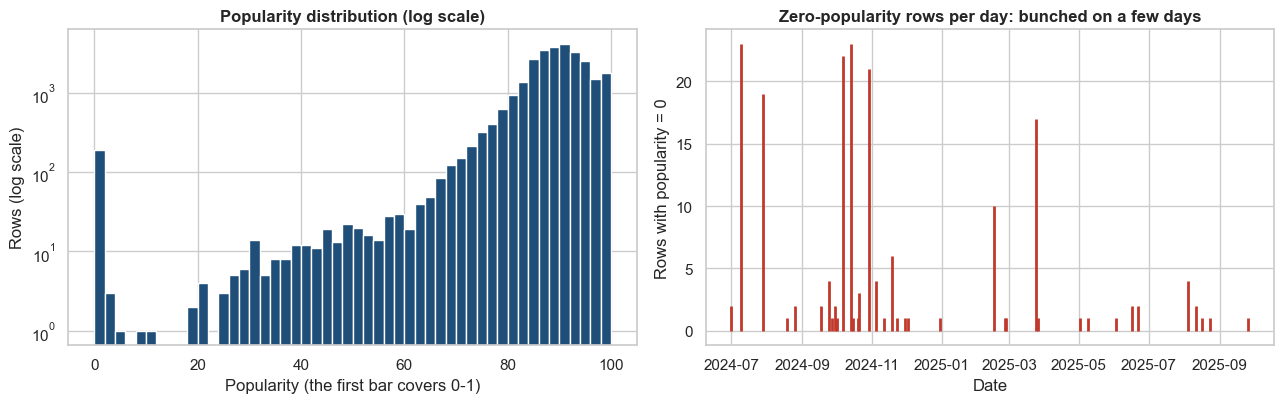

In [21]:
zero_mask = df["popularity"] == 0
zeros = df[zero_mask]
print(f"Rows with popularity = 0 : {len(zeros):,} ({len(zeros) / len(df):.2%} of all rows)")
print(f"Distinct dates affected  : {zeros['date'].nunique()} of {df['date'].nunique()}")
print(f"Distinct tracks affected : {zeros['track_id'].nunique()}")

# Compare each zero with the same track's typical popularity on its other (non-zero) days
typical = df[~zero_mask].groupby("track_id")["popularity"].median().rename("typical_popularity")
zeros = zeros.join(typical, on="track_id")
print(f"\nZeros whose track has no non-zero history at all: {int(zeros['typical_popularity'].isna().sum())}")
print("Typical (median) popularity of the affected tracks on their normal days:")
print(zeros["typical_popularity"].describe().round(1).to_string())

zeros_per_day = zeros.groupby("date").size().sort_values(ascending=False)
print("\nWorst 5 days:")
print(zeros_per_day.head(5).to_string())

log_check("Validity", "No disguised-missing popularity (0)", "A song inside the Top 50 should not have popularity 0",
          int(zero_mask.sum()), len(df), severity="WARN",
          action="Flag now; Phase 2 treats as missing and fills from the track's own history")

# Two charts: the distribution, and the zeros over time
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df["popularity"], bins=range(0, 102, 2), color=COLORS["primary"])
axes[0].set_yscale("log")                                  # log scale so the small bar at 0 is still visible
axes[0].set_title("Popularity distribution (log scale)")
axes[0].set_xlabel("Popularity (the first bar covers 0-1)")
axes[0].set_ylabel("Rows (log scale)")

zeros_by_date = zeros.groupby("date").size()
axes[1].vlines(zeros_by_date.index, 0, zeros_by_date.values, color=COLORS["bad"], lw=2)
axes[1].set_title("Zero-popularity rows per day: bunched on a few days")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Rows with popularity = 0")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p1_popularity_zeros.png", dpi=150)
plt.show()

### Step 7.3 - Duration: unusual does not mean wrong

**What this code is:** A look at the shortest and longest tracks (listed once per track, not once per day) and a histogram of duration in minutes.

**Why we need it:** The range check passed, but a few tracks are very short (about 37 seconds) or very long (over 12 minutes). Before treating them as errors we must check whether they are *real*. An **outlier** is unusual; an **error** is impossible. They are not the same thing.

**What will happen:** Python lists the 6 shortest and 6 longest distinct tracks and draws the duration histogram (log scale, so the thin tails are visible) with the lowest allowed duration and the median marked.

**Expected outcome:** The shortest tracks are real skits and interludes (for example *Breaking News - skit* by Eminem, about 0.6 minutes). The longest include *American Pie* by Don McLean (about 8.6 minutes) and a track of about 12.3 minutes by André 3000. All are genuine.

**Motive:** We **keep** them. In the outlier analysis (Phase 4) we study how duration relates to popularity and rank, using robust methods so that a few extreme tracks do not dominate the results.

6 SHORTEST tracks


,song,artist,days_seen,duration_min
track_id,,,,
794,Breaking News - skit,Eminem,1,0.62
784,Trouble,Eminem,4,0.69
581,Saturn Returns Interlude,Ariana Grande,5,0.70
630,SMOKE HOUR ★ WILLIE NELSON,Beyoncé,3,0.85
638,OH LOUISIANA,Beyoncé,2,0.87
631,MY ROSE,Beyoncé,3,0.89


6 LONGEST tracks


,song,artist,days_seen,duration_min
track_id,,,,
419,"I swear, I Really Wanted To Make A ""Rap"" Album But This Is Literal...",André 3000,1,12.33
140,American Pie,Don McLean,3,8.61
940,Defying Gravity,Wicked Movie Cast & Cynthia Erivo & Ariana Grande,3,7.66
709,Family Matters,Drake,15,7.62
667,Red Leather,Future & Metro Boomin,2,6.91
157,Dear John (Taylor's Version),Taylor Swift,7,6.77


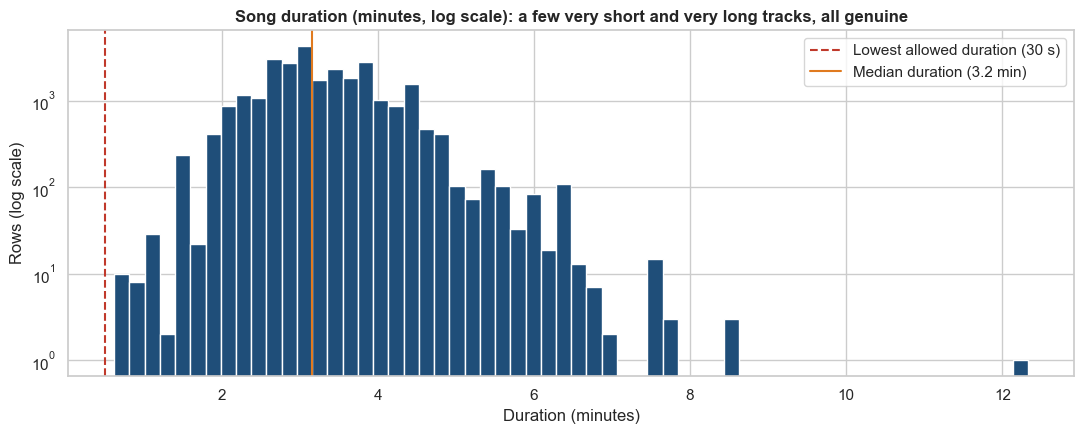

In [22]:
track_duration = (df.groupby("track_id")
                    .agg(song=("song_clean", "first"), artist=("track_credit", "first"),
                         days_seen=("date", "size"),
                         duration_min=("duration_ms", lambda s: s.median() / 60_000))
                    .round({"duration_min": 2}))

print("6 SHORTEST tracks")
display(track_duration.nsmallest(6, "duration_min"))
print("6 LONGEST tracks")
display(track_duration.nlargest(6, "duration_min"))

minutes = df["duration_ms"] / 60_000
fig, ax = plt.subplots()
ax.hist(minutes, bins=60, color=COLORS["primary"])
ax.axvline(RULES["duration_min_ms"] / 60_000, color=COLORS["bad"], ls="--", label="Lowest allowed duration (30 s)")
ax.axvline(minutes.median(), color=COLORS["accent"], ls="-", label=f"Median duration ({minutes.median():.1f} min)")
ax.set_yscale("log")                                    # log scale so the thin tails (very short / very long tracks) are visible
ax.set_title("Song duration (minutes, log scale): a few very short and very long tracks, all genuine")
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Rows (log scale)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p1_duration_hist.png", dpi=150)
plt.show()

### Step 7.4 - Consistency: does a track keep the same attributes over time?

**What this code is:** For every track we count how many *different* values it has for duration, album type, album size (`total_tracks`), explicit flag and cover URL across all the days it appeared.

**Why we need it:** In theory a song's duration or explicit flag never changes. In real data it can: a song may be re-linked to a different release (single vs album version), or an explicit and a clean version may swap. If attributes change, "one row per song" becomes ambiguous - we must decide which value to keep.

**What will happen:** Python groups by `track_id`, counts distinct values per attribute and logs how many tracks are affected (severity INFO: it is a note for Phase 2, not an error).

**Expected outcome:** Out of **944 tracks**, most are perfectly stable, but a minority change: **51** switch `album_type`, **61** switch `total_tracks`, **17** switch `duration_ms`, **12** switch `is_explicit` and **183** (about one in five) switch their cover URL.

**Motive:** Document the issue now, so that Phase 2 can apply a clear rule (planned: use the **most recent value** for track-level descriptors, while the daily analysis keeps each day's own value).

In [23]:
attributes = ["duration_ms", "album_type", "total_tracks", "is_explicit", "album_cover_url"]
distinct_per_track = df.groupby("track_id")[attributes].nunique()        # distinct values per track, per attribute
n_tracks = len(distinct_per_track)

drift_table = pd.DataFrame({
    "tracks_with_changes": (distinct_per_track > 1).sum(),
    "pct_of_tracks": ((distinct_per_track > 1).mean() * 100).round(1),
})
print(f"Tracks examined: {n_tracks:,}")
display(drift_table)

for col in attributes:
    log_check("Consistency", f"{col} is stable per track", "A track keeps one value across all the days it appears",
              int((distinct_per_track[col] > 1).sum()), n_tracks, unit="tracks", severity="INFO",
              action="Phase 2: pick a rule (most recent value) when building one row per track")

Tracks examined: 944


,tracks_with_changes,pct_of_tracks
duration_ms,17,1.80
album_type,51,5.40
total_tracks,61,6.50
is_explicit,12,1.30
album_cover_url,183,19.40


[INFO] duration_ms is stable per track: 17 of 944 tracks (1.80%)
[INFO] album_type is stable per track: 51 of 944 tracks (5.40%)
[INFO] total_tracks is stable per track: 61 of 944 tracks (6.46%)
[INFO] is_explicit is stable per track: 12 of 944 tracks (1.27%)
[INFO] album_cover_url is stable per track: 183 of 944 tracks (19.39%)


## Section 8 - Flags and the Data Quality Scorecard

### Step 8.1 - Add flag columns (we mark problems, we do not delete anything)

**What this code is:** Three new True/False columns that mark rows with known issues: `flag_superseded_snapshot` (the earlier block on a double-snapshot date), `flag_popularity_zero` (the disguised-missing zeros) and `flag_unexpected_album_type` (anything other than single/album).

**Why we need it:** Deleting or editing rows during validation hides what happened. Flags keep the full history visible: Phase 2 can decide what to drop or repair, and Power BI can even show "how many rows were affected".

**What will happen:** Python creates the three columns and counts how many rows each one marks.

**Expected outcome:** `flag_superseded_snapshot` = **50** rows, `flag_popularity_zero` = **189** rows, `flag_unexpected_album_type` = **42** rows. The dataset still has all **27,800** rows.

**Motive:** Traceability. Every cleaning decision in Phase 2 can point to a flag, and every flag can be explained in the research paper.

In [24]:
blocks_that_day = df.groupby("date")["snapshot_seq"].transform("max")     # how many blocks does this row's date have?

df["flag_superseded_snapshot"] = (df["snapshot_seq"] < blocks_that_day).astype(bool)    # True for the earlier block(s)
df["flag_popularity_zero"]     = (df["popularity"] == 0).astype(bool)

album_clean = df["album_type"].astype("string").str.strip().str.casefold()
df["flag_unexpected_album_type"] = (~album_clean.isin(RULES["allowed_album_types"]).fillna(False).astype(bool)).astype(bool)

flag_cols = [c for c in df.columns if c.startswith("flag_")]
print(df[flag_cols].sum().rename("rows_flagged").to_frame())
print("\nTotal rows still in the dataset:", f"{len(df):,}")

                            rows_flagged
flag_superseded_snapshot              50
flag_popularity_zero                 189
flag_unexpected_album_type            42

Total rows still in the dataset: 27,800


### Step 8.2 - The Data Quality Scorecard

**What this code is:** One table that gathers every check we logged, with its status, how many items broke the rule and what we plan to do. Below it, a count of PASS / WARN / INFO / FAIL.

**Why we need it:** A scorecard is the single page you can show to a manager, mentor or interviewer to prove the data was audited. It also becomes the "Data Validation" section of the research paper.

**What will happen:** Python turns the `dq_log` list into a table, sorts the problems to the top and prints a summary.

**Expected outcome:** **0 FAIL**, 17 PASS, 8 WARN and 6 INFO (31 checks in total). The WARN items are the 4 missing days, the double-snapshot date and its duplicate rows, the song credits that changed over time, the zero-popularity rows and the `compilation` album type. The INFO notes are the shared titles and the attributes that change over time.

**Motive:** Honest reporting. "The data is clean" is a claim; a scorecard is evidence.

In [25]:
scorecard = pd.DataFrame(dq_log)
status_order = {"FAIL": 0, "WARN": 1, "INFO": 2, "PASS": 3}
scorecard["_order"] = scorecard["status"].map(status_order)
scorecard = (scorecard.sort_values(["_order", "dimension", "check"])
                      .drop(columns="_order").reset_index(drop=True))

display(scorecard[["status", "dimension", "check", "affected", "total", "unit", "pct_affected", "action"]])

print("Summary of statuses:")
print(scorecard["status"].value_counts().reindex(["PASS", "WARN", "INFO", "FAIL"], fill_value=0).to_string())

,status,dimension,check,affected,total,unit,pct_affected,action
0,WARN,Coverage,Exactly 50 rows per date,1,555,days,0.18,Investigate (Step 5.2) and keep one snapshot per date
1,WARN,Coverage,No missing calendar days,4,559,days,0.72,Do not invent rows; make time features gap-aware
2,WARN,Uniqueness,A song keeps one artist credit over time,29,973,title+credit pairs,2.98,Merged into one track_id (Step 6.5)
3,WARN,Uniqueness,No identical rows,10,27800,rows,0.04,Resolved by keeping one snapshot per date
4,WARN,Uniqueness,No rank repeated within a date,50,27800,rows,0.18,Keep one snapshot per date (Step 5.2)
5,WARN,Uniqueness,No song repeated within a date,48,27800,rows,0.17,Resolved by keeping one snapshot per date
6,WARN,Validity,No disguised-missing popularity (0),189,27800,rows,0.68,Flag now; Phase 2 treats as missing and fills from the track's own...
7,WARN,Validity,album_type is Single or Album,42,27800,rows,0.15,Keep as its own category; group with 'album' only where a test nee...
8,INFO,Consistency,Titles with several artist credits,34,938,titles,3.62,Decide per title: same song or different songs (below)
9,INFO,Consistency,album_cover_url is stable per track,183,944,tracks,19.39,Phase 2: pick a rule (most recent value) when building one row per...


Summary of statuses:
status
PASS    17
WARN     8
INFO     6
FAIL     0


### Step 8.3 - Decision log: what we learned and what we will do in Phase 2

No code here. This table is the most valuable output of Phase 1: it turns findings into decisions that you can defend in the research paper and in an interview.

| # | Finding | Evidence | Decision for Phase 2 |
|---|---|---|---|
| 1 | Dates are text in DD-MM-YYYY | 27,800 values, 0 parse failures | Always parse with `format="%d-%m-%Y"` |
| 2 | 2025-03-01 has two 50-row blocks | Only 10 of 50 ranks identical; block 1 is closer to 28-Feb, block 2 closer to 02-Mar | Keep the **latest** block, drop the earlier one (50 rows) |
| 3 | 4 calendar days are missing (14-Mar-25, 25-Mar-25, 11-Jul-25, 13-Aug-25) | 555 of 559 days present | Do not invent rows; make "days on chart", streaks and rolling windows gap-aware |
| 4 | Popularity = 0 on 189 rows, bunched on 38 days | The same tracks score about 83 on their other days | Treat as missing; fill from the track's own neighbouring days; keep `flag_popularity_zero` |
| 5 | `compilation` album type (42 rows) is not in the brief | A handful of seasonal / classic tracks | Keep as its own category; merge into "album" only where a test needs bigger groups |
| 6 | Artists are joined with ` & `; commas belong to names | `Tyler, The Creator`; `Earth, Wind & Fire` | Split on ` & ` with a protected-names list |
| 7 | One artist written two ways | `Charli xcx` (181 rows) vs `Charli XCX` (30 rows) | Use the most frequent spelling |
| 8 | A title is not a unique ID, and one song can carry different artist credits on different days | 34 titles have 2+ credits: 28 are the same song (e.g. *I Had Some Help*: 103 + 95 days), 6 are different songs | Identity = `track_id` (973 title+credit pairs resolve to 944 songs) |
| 9 | Some track attributes change over time | Step 7.4 | Use the most recent value for track-level descriptors |
| 10 | Extreme durations and album sizes are real | Skits under 1 minute, a 12-minute track, a 119-track compilation | Keep them; use robust statistics in the EDA |
| 11 | `single` does not always mean one track | Step 7.1 cross-table | Analyze `album_type` and `total_tracks` as separate attributes |

## Section 9 - Save the validated data

### Step 9.1 - Write the outputs to disk

**What this code is:** Three file-saving commands: the validated dataset (Parquet **and** CSV) and the Data Quality Scorecard (CSV).

**Why we need it:** Phase 2 must start from *this* validated version, not from the raw file. Parquet is a compact, fast format that remembers data types (dates stay dates). CSV is included because it opens everywhere, including Excel and Power BI.

**What will happen:** Python removes the temporary list column, orders the columns logically and writes `data/interim/playlist_validated.parquet`, `data/interim/playlist_validated.csv` and `reports/data_quality_scorecard.csv`.

**Expected outcome:** Three files appear on disk; the printout shows **27,800 rows** and **24 columns**.

**Motive:** Never rely on a notebook's memory. Saved files make each phase independent, repeatable and easy to hand over.

In [26]:
# Remove the temporary list column (lists do not save cleanly to CSV)
df_out = df.drop(columns=["artist_list"])

# A logical column order: original columns first, then cleaned / derived columns, then flags
original_cols = list(EXPECTED_COLUMNS)
derived_cols  = ["song_clean", "artist_clean", "primary_artist", "artist_count", "artists_all",
                 "song_key", "artist_key", "track_key", "track_id", "track_credit", "snapshot_seq"]
flag_cols     = [c for c in df_out.columns if c.startswith("flag_")]
df_out = df_out[original_cols + derived_cols + flag_cols]

parquet_path   = INTERIM_DIR / "playlist_validated.parquet"
csv_path       = INTERIM_DIR / "playlist_validated.csv"
scorecard_path = REPORTS_DIR / "data_quality_scorecard.csv"

df_out.to_parquet(parquet_path, index=False)
df_out.to_csv(csv_path, index=False)
scorecard.to_csv(scorecard_path, index=False)

print(f"Saved {len(df_out):,} rows x {df_out.shape[1]} columns")
for p in (parquet_path, csv_path, scorecard_path):
    print(f"  {p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size / 1024:,.0f} KB)")

Saved 27,800 rows x 24 columns
  data\interim\playlist_validated.parquet  (611 KB)
  data\interim\playlist_validated.csv  (8,173 KB)
  reports\data_quality_scorecard.csv  (5 KB)


### Step 9.2 - Prove the save worked (round-trip test)

**What this code is:** We read the Parquet file back and compare it with what we saved.

**Why we need it:** "File saved" does not prove "file correct". Reloading is a cheap safety test that catches missing columns, changed types or lost rows.

**What will happen:** Python re-loads the file, compares row count, columns and the `date` data type, and spot-checks that the 2025-03-01 flag is right.

**Expected outcome:** Four lines starting with `OK`.

**Motive:** Trust, but verify. This habit is what separates a notebook from a pipeline.

In [27]:
check = pd.read_parquet(parquet_path)

assert len(check) == len(df_out) == len(df_raw), "row count changed"
assert list(check.columns) == list(df_out.columns), "columns changed"
assert str(check["date"].dtype).startswith("datetime64"), "date is no longer a datetime"
assert check.loc[check["date"] == "2025-03-01", "flag_superseded_snapshot"].sum() == 50, "snapshot flag is wrong"

print("OK  row count identical to the raw file:", f"{len(check):,}")
print("OK  all columns present:", check.shape[1])
print("OK  date column is a real datetime:", check["date"].dtype)
print("OK  2025-03-01: the earlier 50-row block is flagged")

OK  row count identical to the raw file: 27,800
OK  all columns present: 24
OK  date column is a real datetime: datetime64[ns]
OK  2025-03-01: the earlier 50-row block is flagged


## Phase 1 complete

### What you now have
- `data/interim/playlist_validated.parquet` (and `.csv`): typed, standardized and flagged, with **no rows deleted**
- `reports/data_quality_scorecard.csv`: the evidence for every check
- `reports/figures/`: three validation charts (rows per day, popularity zeros, duration)

### What this dataset taught us
1. Dates are **day-month-year**, so the format must always be stated explicitly.
2. One date (2025-03-01) was captured **twice**; four calendar days are **missing**.
3. **189 popularity zeros** are collection glitches, not real scores.
4. A third album type, `compilation`, exists although the brief lists only Single / Album.
5. A **song title is not an ID**, and even title + artist is not enough: the same song can be credited differently on different days. We resolved this into `track_id` (973 → 944 songs).
6. Artists are separated by ` & ` and never by commas, with a few band names that must be protected.

### Check your understanding (answer in your own words)
1. Why can't `drop_duplicates()` fix the 2025-03-01 problem, and what did we do instead?
2. Why is `Tyler, The Creator` a trap for a comma-based artist splitter?
3. What is the difference between an *outlier* and an *error*? Give one example from this data.
4. Why did the popularity range check pass even though the zeros are wrong?

### Next: Phase 2 - Cleaning & Feature Engineering
We apply the decision log, then build the metrics the brief asks for: **Days on Chart, Average Rank, Best Rank, Rank Volatility Index, Popularity Trend Score (rolling average) and Duration in minutes**, plus rank movement, entry/exit flags, streaks and the track-, artist- and date-level tables that Streamlit and Power BI will read.